##Theoretical

Q1. What is Boosting in Machine Learning?

Ans.Definition: Boosting is an ensemble machine learning technique that converts a set of weak learners into a strong learner.   Working Mechanism: It builds models sequentially, where each new model is trained to correct the errors (residuals) made by the previous models.   Key Idea: Instances that are misclassified by earlier models are given higher weights so that subsequent models focus more on hard-to-predict examples.  

Q2. How does Boosting differ from Bagging?

Ans.Training Process: Bagging trains base models independently and in parallel (e.g., Random Forest), whereas Boosting trains models sequentially (one after the other).   Data Sampling: Bagging uses bootstrap sampling (with replacement) to create subsets of data, while Boosting typically uses the entire dataset, adjusting sample weights iteratively.   Objective: Bagging primarily reduces variance (preventing overfitting), whereas Boosting primarily reduces bias (improving accuracy).

Q3. What is the key idea behind AdaBoost?

Ans.Adaptive Reseeding/Reweighting: AdaBoost (Adaptive Boosting) dynamically adjusts the weights of training data after every classifier is built.   Focus on Errors: Points that are incorrectly classified get increased weights, forcing the next weak learner to pay more attention to them.   Final Combination: Individual weak models (usually decision stumps) are combined using a weighted majority vote based on their individual classification accuracy

Q4. Explain the working of AdaBoost with an example.

Ans.Step 1: Initialize all data points with equal weights. Train a base classifier (e.g., a shallow decision tree) on the weighted data.   Step 2: Calculate the total error of the classifier and assign a weight to the model itself based on how well it performed.   Step 3: Increase the weights of the misclassified data points and decrease the weights of correctly classified points.   Example: In a spam detection task, if the first model fails to catch specific complex spam emails, those missed emails are heavily weighted so the next model prioritizes learning them.

Q5. What is Gradient Boosting, and how is it different from AdaBoost?

Ans.Gradient Boosting: An ensemble technique that builds models sequentially by fitting new base learners to the pseudo-residuals (gradients of the loss function) of the previous step.   Difference in Optimization: While AdaBoost updates data weights based on classification errors (often using exponential loss), Gradient Boosting frames boosting as a numerical optimization problem, minimizing any differentiable loss function using gradient descent.

Q6. What is the loss function in Gradient Boosting?

Ans.Purpose: The loss function measures how well the model's predictions match the actual target values.   Flexibility: Gradient Boosting can use various differentiable loss functions depending on the problem type.   Common Examples: Mean Squared Error (MSE) or Huber loss for regression tasks, and Binary/Multiclass Cross-Entropy (Log Loss) for classification tasks.

Q7. How does XGBoost improve over traditional Gradient Boosting?

Ans.Regularization: XGBoost includes L1 ($L_1$) and L2 ($L_2$) regularization penalties in its objective function to prevent overfitting.   Speed & Efficiency: It supports parallelization of tree construction and uses hardware optimization techniques like cache awareness and out-of-core computation.   Missing Value Handling: XGBoost has a built-in routine to automatically learn the optimal direction for handling missing data values.

Q8. What is the difference between XGBoost and CatBoost?

Ans.Categorical Handling: CatBoost natively handles categorical features using advanced algorithms (ordered target encoding), whereas XGBoost requires manual pre-processing (like one-hot encoding or label encoding).   Tree Structure: XGBoost builds level-wise (symmetric or asymmetric depending on setup), while standard CatBoost primarily builds symmetric trees to reduce overfitting.   Speed: CatBoost is often exceptionally fast out-of-the-box for datasets containing many categorical variables.

Q9. What are some real-world applications of Boosting techniques?

Ans.Finance: Credit scoring, risk assessment, and detecting fraudulent credit card transactions.   Search & Recommendation: Ranking search results (e.g., web search engines like Yahoo/Bing used LambdaMART) and recommendation systems.   Healthcare: Predicting disease onset, patient readmission risks, and medical diagnostics

Q10. How does regularization help in XGBoost?

Ans.Controlling Complexity: It adds penalty terms for model complexity (based on the number of leaves and leaf weights) to the objective function.   Preventing Overfitting: Regularization shrinks the weights of leaf nodes, creating a smoother model that generalizes better to unseen test data.   Variance Reduction: It prevents individual trees from growing overly deep or capturing noise in the training dataset.  

Q11. What are some hyperparameters to tune in Gradient Boosting models?

Ans.Learning Rate (Shrinkage): Determines the step size shrinkage used in updates, balancing training speed and generalization.   Number of Estimators: The total number of sequential trees to build.   Max Depth / Tree Complexity: Limits how deep individual trees can grow to control model complexity and prevent overfitting.  

Q12. What is the concept of Feature Importance in Boosting?

Ans.Definition: A metric that scores how useful or valuable each feature was in constructing the boosted decision trees.   Calculation Methods: Typically measured using gain (total reduction of loss brought by a feature), coverage (number of samples affected by splits on that feature), or frequency (how often a feature appears in the trees).   Use Case: Helps in feature selection, model interpretability, and understanding underlying data patterns.

Q13. Why is CatBoost efficient for categorical data?   

Ans.Ordered Target Encoding: CatBoost converts categorical columns into numerical values using a specialized target statistics method that prevents target leakage and overfitting.   Combinatorial Features: It automatically considers combinations of categorical features during tree splitting, capturing complex interactions without manual engineering.   Reduced Preprocessing: It eliminates the need for extensive one-hot encoding, which drastically reduces memory consumption and training time on high-cardinality data.   

##Practical

In [1]:
#Q14. Train an AdaBoost Classifier on a sample dataset and print model accuracy?
#Ans.
from sklearn.ensemble import AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = AdaBoostClassifier(random_state=42)
model.fit(X_train, y_train)
print(accuracy_score(y_test, model.predict(X_test)))

0.9


In [2]:
#Q15. Train an AdaBoost Regressor and evaluate performance using Mean Absolute Error (MAE)?
#Ans.
from sklearn.ensemble import AdaBoostRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

X, y = make_regression(n_samples=100, n_features=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = AdaBoostRegressor(random_state=42)
model.fit(X_train, y_train)
print(mean_absolute_error(y_test, model.predict(X_test)))

113.30282044766334


In [3]:
#Q16. Train a Gradient Boosting Classifier on the Breast Cancer dataset and print feature importance?
#Ans.
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
model = GradientBoostingClassifier(random_state=42)
model.fit(data.data, data.target)
print(model.feature_importances_)

[2.62081861e-04 2.78518853e-02 3.23360461e-04 6.47260991e-04
 9.97183313e-05 1.43145647e-03 5.67210930e-04 1.31764547e-01
 9.35742196e-04 2.62368747e-04 3.06665558e-03 4.08567871e-03
 1.73937647e-03 8.32678414e-03 5.26102474e-04 6.94362926e-04
 2.13268500e-03 4.43333939e-03 1.84612953e-03 1.27988925e-03
 4.43226458e-01 3.50360232e-02 1.50527636e-01 2.94257281e-02
 7.25578124e-03 7.76821542e-04 1.38583982e-02 1.26939670e-01
 1.82591800e-04 4.94256678e-04]


In [4]:
#Q17. Train a Gradient Boosting Regressor and evaluate using R-Squared Score?
#Ans.
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X, y = make_regression(n_samples=100, n_features=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)
print(r2_score(y_test, model.predict(X_test)))

0.5691854090932759


In [5]:
#Q18. Train an XGBoost Classifier on a dataset and compare accuracy with Gradient Boosting?
#Ans.
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
xgb = XGBClassifier(random_state=42).fit(X_train, y_train)
gbc = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)
print(accuracy_score(y_test, xgb.predict(X_test)), accuracy_score(y_test, gbc.predict(X_test)))

0.9 0.9


In [8]:
#Q19. Train a CatBoost Classifier and evaluate using F1-Score?
#Ans.
!pip install catboost
from catboost import CatBoostClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = CatBoostClassifier(verbose=0, random_state=42)
model.fit(X_train, y_train)
print(f1_score(y_test, model.predict(X_test)))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 21.5 MB/s  0:00:04
0.875


In [9]:
#Q20. Train an XGBoost Regressor and evaluate using Mean Squared Error (MSE)?
#Ans.
from xgboost import XGBRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X, y = make_regression(n_samples=100, n_features=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = XGBRegressor(random_state=42)
model.fit(X_train, y_train)
print(mean_squared_error(y_test, model.predict(X_test)))

22001.87937483636


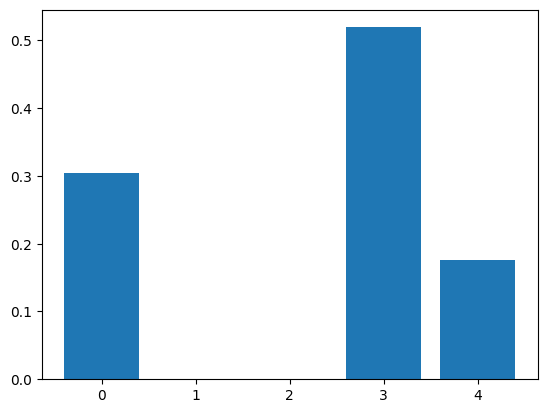

In [10]:
#Q21. Train an AdaBoost Classifier and visualize feature importance?
#Ans.
from sklearn.ensemble import AdaBoostClassifier
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=100, n_features=5, random_state=42)
model = AdaBoostClassifier(random_state=42).fit(X, y)
plt.bar(range(len(model.feature_importances_)), model.feature_importances_)
plt.show()

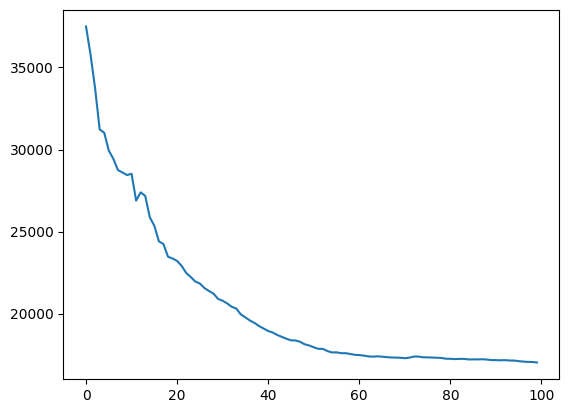

In [11]:
#Q22. Train a Gradient Boosting Regressor and plot learning curves?
#Ans.
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

X, y = make_regression(n_samples=100, n_features=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
errors = [mean_squared_error(y_test, y_pred) for y_pred in model.staged_predict(X_test)]
plt.plot(errors)
plt.show()

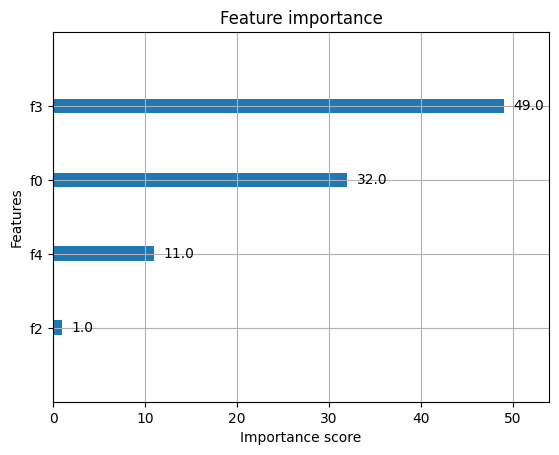

In [12]:
#Q23. Train an XGBoost Classifier and visualize feature importance?
#Ans.
from xgboost import XGBClassifier, plot_importance
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=100, n_features=5, random_state=42)
model = XGBClassifier(random_state=42).fit(X, y)
plot_importance(model)
plt.show()

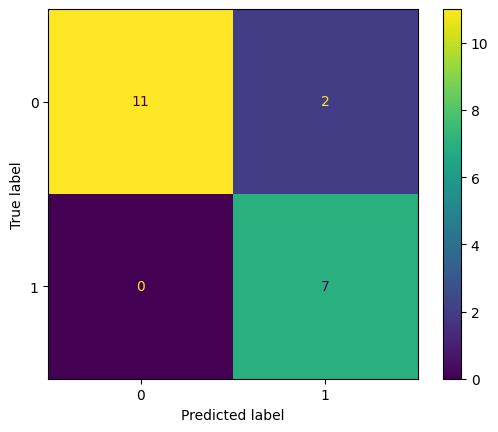

In [13]:
#Q24. Train a CatBoost Classifier and plot the confusion matrix?
#Ans.
from catboost import CatBoostClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = CatBoostClassifier(verbose=0, random_state=42).fit(X_train, y_train)
ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test))
plt.show()

In [14]:
#Q25. Train an AdaBoost Classifier with different numbers of estimators and compare accuracy?
#Ans.
from sklearn.ensemble import AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
for n in [10, 50, 100]:
    model = AdaBoostClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    print(n, accuracy_score(y_test, model.predict(X_test)))

10 0.9
50 0.9
100 0.9


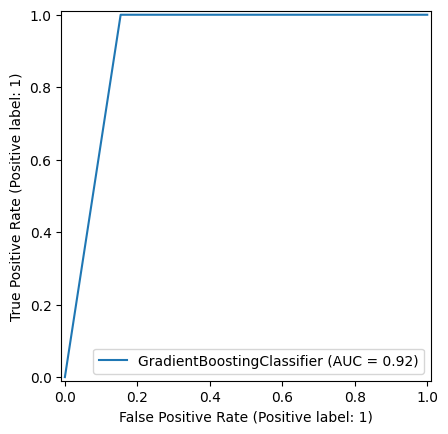

In [15]:
#Q26. Train a Gradient Boosting Classifier and visualize the ROC curve?
#Ans.
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.show()

In [16]:
#Q27. Train an XGBoost Regressor and tune the learning rate using GridSearchCV?
#Ans.
from xgboost import XGBRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import GridSearchCV

X, y = make_regression(n_samples=100, n_features=10, random_state=42)
grid = GridSearchCV(XGBRegressor(random_state=42), {'learning_rate': [0.01, 0.1, 0.2]}, cv=3)
grid.fit(X, y)
print(grid.best_params_)

{'learning_rate': 0.1}


In [17]:
#Q28. Train a CatBoost Classifier on an imbalanced dataset and compare performance with class weighting?
#Ans.
from catboost import CatBoostClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import f1_score

X, y = make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=42)
m1 = CatBoostClassifier(verbose=0, random_state=42).fit(X, y)
m2 = CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=42).fit(X, y)
print(f1_score(y, m1.predict(X)), f1_score(y, m2.predict(X)))

0.9951219512195122 1.0


In [18]:
#Q29. Train an AdaBoost Classifier and analyze the effect of different learning rates?
#Ans.
from sklearn.ensemble import AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=100, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
for lr in [0.01, 0.1, 1.0]:
    model = AdaBoostClassifier(learning_rate=lr, random_state=42).fit(X_train, y_train)
    print(lr, accuracy_score(y_test, model.predict(X_test)))

0.01 0.9
0.1 0.9
1.0 0.9


In [19]:
#Q30. Train an XGBoost Classifier for multi-class classification and evaluate using log-loss?
#Ans.
from xgboost import XGBClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

X, y = make_classification(n_samples=100, n_features=20, n_classes=3, n_informative=5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = XGBClassifier(objective='multi:softprob', random_state=42).fit(X_train, y_train)
print(log_loss(y_test, model.predict_proba(X_test)))

0.9855425189174747
